# Pipeline Project

You will be using the provided data to create a machine learning model pipeline.

You must handle the data appropriately in your pipeline to predict whether an
item is recommended by a customer based on their review.
Note the data includes numerical, categorical, and text data.

You should ensure you properly train and evaluate your model.

## The Data

The dataset has been anonymized and cleaned of missing values.

There are 8 features for to use to predict whether a customer recommends or does
not recommend a product.
The `Recommended IND` column gives whether a customer recommends the product
where `1` is recommended and a `0` is not recommended.
This is your model's target/

The features can be summarized as the following:

- **Clothing ID**: Integer Categorical variable that refers to the specific piece being reviewed.
- **Age**: Positive Integer variable of the reviewers age.
- **Title**: String variable for the title of the review.
- **Review Text**: String variable for the review body.
- **Positive Feedback Count**: Positive Integer documenting the number of other customers who found this review positive.
- **Division Name**: Categorical name of the product high level division.
- **Department Name**: Categorical name of the product department name.
- **Class Name**: Categorical name of the product class name.

The target:
- **Recommended IND**: Binary variable stating where the customer recommends the product where 1 is recommended, 0 is not recommended.

## Imports

In [1]:
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style='whitegrid')

# Same 3 folds for cross-validation and grid search, so the cached
# spaCy output from the baseline can be reused during fine-tuning
CV_FOLDS = StratifiedKFold(n_splits=3)
CACHE_DIR = 'cache'

## Load Data

In [2]:
# Load data
df = pd.read_csv(
    'data/reviews.csv',
)

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 18442 entries, 0 to 18441
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Clothing ID              18442 non-null  int64
 1   Age                      18442 non-null  int64
 2   Title                    18442 non-null  str  
 3   Review Text              18442 non-null  str  
 4   Positive Feedback Count  18442 non-null  int64
 5   Division Name            18442 non-null  str  
 6   Department Name          18442 non-null  str  
 7   Class Name               18442 non-null  str  
 8   Recommended IND          18442 non-null  int64
dtypes: int64(4), str(5)
memory usage: 1.3 MB


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name,Recommended IND
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses,0
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants,1
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses,1
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses,0
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits,1


## Preparing features (`X`) & target (`y`)

In [3]:
data = df

# separate features from labels
X = data.drop('Recommended IND', axis=1)
y = data['Recommended IND'].copy()

print('Labels:', y.unique())
print('Features:')
display(X.head())

Labels: [0 1]
Features:


,Clothing ID,Age,Title,Review Text,Positive Feedback Count,Division Name,Department Name,Class Name
0,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,0,General,Dresses,Dresses
1,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",0,General Petite,Bottoms,Pants
2,847,47,Flattering shirt,This shirt is very flattering to all due to th...,6,General,Tops,Blouses
3,1080,49,Not for the very petite,"I love tracy reese dresses, but this one is no...",4,General,Dresses,Dresses
4,858,39,Cagrcoal shimmer fun,I aded this in my basket at hte last mintue to...,1,General Petite,Tops,Knits


In [4]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    shuffle=True,
    random_state=27,
)

# Your Work

## Data Exploration

All exploration uses the **training data only** (`X_train`, `y_train`), so the test set stays unseen until the final evaluation.

In [5]:
# Combine features and target for easier group comparisons
train_df = X_train.assign(recommended=y_train)
train_df['review_words'] = (
    train_df['Review Text'].fillna('').str.split().str.len()
)
train_df['title_words'] = train_df['Title'].fillna('').str.split().str.len()

NUMERIC_COLS = ['Age', 'Positive Feedback Count']
CATEGORICAL_COLS = ['Division Name', 'Department Name', 'Class Name']

# Missing values and overview (Clothing ID is a label, so it is excluded)
display(X_train.isna().sum().to_frame('missing values'))
display(X_train.drop(columns='Clothing ID').describe(include='all').T)

,missing values
Clothing ID,0
Age,0
Title,0
Review Text,0
Positive Feedback Count,0
Division Name,0
Department Name,0
Class Name,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,16597.0,NaN,NaN,NaN,43.370609,12.21624,18.0,34.0,42.0,52.0,99.0
Title,16597,11955,Love it!,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review Text,16597,16594,I bought this shirt at the store and after goi...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Positive Feedback Count,16597.0,NaN,NaN,NaN,2.713924,6.014332,0.0,0.0,1.0,3.0,122.0
Division Name,16597,2,General,10497,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department Name,16597,6,Tops,7818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class Name,16597,14,Dresses,4845,NaN,NaN,NaN,NaN,NaN,NaN,NaN


There are no missing values in the training data. The pipeline will still include imputers, so new reviews with gaps can be handled.

### Target balance

,count,share
Recommended IND,,
0,3062,0.184
1,13535,0.816


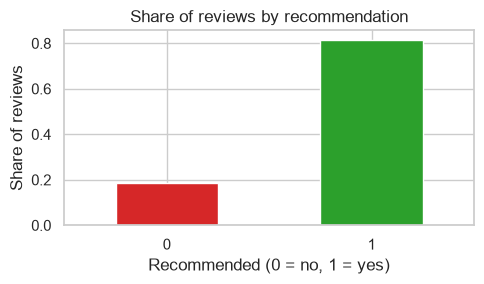

In [6]:
target_share = y_train.value_counts(normalize=True).sort_index()
display(pd.DataFrame({
    'count': y_train.value_counts().sort_index(),
    'share': target_share.round(3),
}))

ax = target_share.plot(
    kind='bar', color=['tab:red', 'tab:green'], figsize=(5, 3),
)
ax.set_title('Share of reviews by recommendation')
ax.set_xlabel('Recommended (0 = no, 1 = yes)')
ax.set_ylabel('Share of reviews')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

About **82 %** of reviews recommend the product. A model that always predicts "recommended" would already reach 82 % accuracy. The model is therefore evaluated with precision, recall and F1 for both classes, and the minority class (not recommended) gets extra weight during training.

### Numerical features

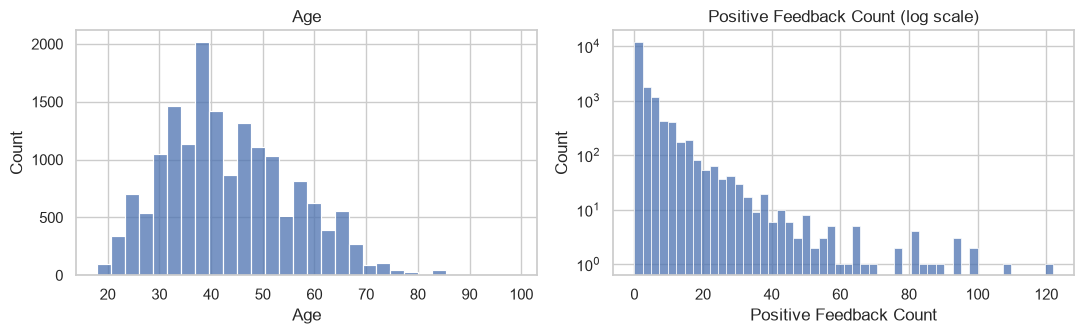

Age        Positive Feedback Count       
              mean median                    mean median
recommended                                             
0            42.57   41.0                    3.52    1.0
1            43.55   42.0                    2.53    1.0

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(train_df['Age'], bins=30, ax=axes[0])
axes[0].set_title('Age')
sns.histplot(train_df['Positive Feedback Count'], bins=50, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Positive Feedback Count (log scale)')
plt.tight_layout()
plt.show()

display(
    train_df.groupby('recommended')[NUMERIC_COLS]
    .agg(['mean', 'median'])
    .round(2)
)

- `Age` is roughly bell-shaped (median about 41) and almost identical for both classes.
- `Positive Feedback Count` is heavily right-skewed: most reviews have 0 votes, a few have more than 100. Not-recommended reviews receive slightly more votes on average (about 3.5 vs. 2.5).
- Both features carry little signal on their own. They are imputed with the median (robust to skew) and scaled in the pipeline.

### Categorical features

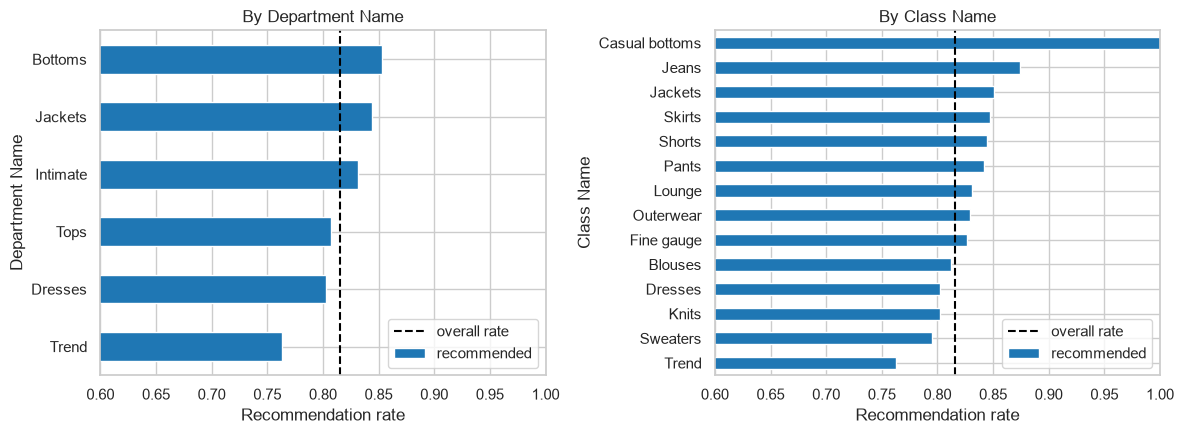

,count,recommendation_rate
Division Name,,
General,10497,0.813
General Petite,6100,0.820


,count,recommendation_rate
Department Name,,
Tops,7818,0.807
Dresses,4845,0.803
Bottoms,2852,0.853
Jackets,813,0.844
Intimate,172,0.831
Trend,97,0.763


,count,recommendation_rate
Class Name,,
Dresses,4845,0.803
Knits,3554,0.802
Blouses,2337,0.812
Sweaters,1095,0.795
Pants,1041,0.841
Jeans,885,0.875
Fine gauge,832,0.827
Skirts,693,0.847
Jackets,549,0.851


In [8]:
def plot_recommendation_rate(df, column, ax):
    """Plot the recommendation rate per category, sorted from low to high."""
    rates = df.groupby(column)['recommended'].mean().sort_values()
    rates.plot(kind='barh', ax=ax, color='tab:blue')
    ax.axvline(df['recommended'].mean(), color='black', linestyle='--',
               label='overall rate')
    ax.set_xlim(0.6, 1.0)
    ax.set_xlabel('Recommendation rate')
    ax.set_title(f'By {column}')
    ax.legend(loc='lower right')


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_recommendation_rate(train_df, 'Department Name', axes[0])
plot_recommendation_rate(train_df, 'Class Name', axes[1])
plt.tight_layout()
plt.show()

for col in CATEGORICAL_COLS:
    display(
        train_df.groupby(col)['recommended']
        .agg(count='size', recommendation_rate='mean')
        .round(3)
        .sort_values('count', ascending=False)
    )

In [9]:
# Clothing ID behaves like a categorical label with many rare values
id_counts = X_train['Clothing ID'].value_counts()
print('Unique Clothing IDs in training:', id_counts.size)
print('IDs with fewer than 5 training reviews:', (id_counts < 5).sum())
print(
    'Test reviews with an ID unseen in training:',
    (~X_test['Clothing ID'].isin(id_counts.index)).sum(),
)

Unique Clothing IDs in training: 520
IDs with fewer than 5 training reviews: 250
Test reviews with an ID unseen in training: 13


- Recommendation rates differ only a little between categories (e.g. Bottoms about 85 %, Trend about 76 %). Small groups like *Trend* and *Intimate* have few reviews, and the 100 % for *Casual bottoms* comes from a single review, so these rates are unreliable.
- `Clothing ID` is a product label, not a quantity, so it is one-hot encoded like the other categorical features. Many IDs are rare, and some test IDs never appear in training. The encoder therefore groups rare IDs (`min_frequency`) and ignores unknown ones (`handle_unknown`).

### Text features

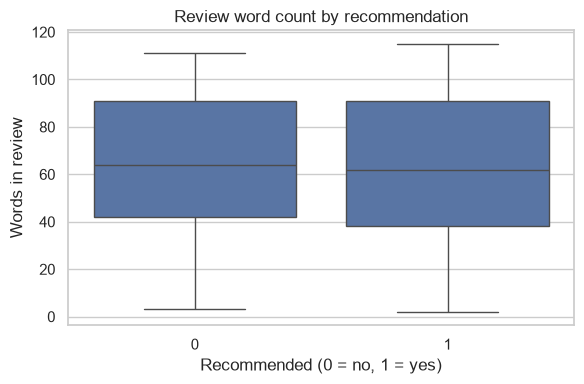

,share with negation
recommended,
0,0.713
1,0.524


In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=train_df, x='recommended', y='review_words', ax=ax)
ax.set_title('Review word count by recommendation')
ax.set_xlabel('Recommended (0 = no, 1 = yes)')
ax.set_ylabel('Words in review')
plt.tight_layout()
plt.show()

# Share of reviews that contain a negation word
negation_pattern = r"\b(?:not|no|never)\b|n't"
negation_share = (
    train_df['Review Text']
    .str.contains(negation_pattern, case=False, regex=True)
    .groupby(train_df['recommended'])
    .mean()
    .round(3)
)
display(negation_share.to_frame('share with negation'))

In [11]:
# Example reviews from each class
for label in [0, 1]:
    print(f'--- Recommended = {label} ---')
    examples = train_df.loc[train_df['recommended'] == label,
                            ['Title', 'Review Text']].sample(2, random_state=1)
    for title, text in examples.itertuples(index=False):
        print(f'{title}: {text[:250]}...\n')

--- Recommended = 0 ---
Huge: I love baseball tees and this looked like a more refined version, but it was huge and shapeless.  nice material and fabric but this one is going back....

Not too bad..: I purchased the grey in a medium, i normally wear an 8 or 10 in tops, 36 c.. i found it to fit quite well, but it has the shape that seems common at retailer lately in that it is shorter and more boxy. so if you have a longer torso(like me), you may ...

--- Recommended = 1 ---
I love the feel of this tunic!: I was so excited to receive the playa tunic in the mail! i love the colors and the flowy bottom and raw edges. this tunic could be worn as a dress or with jeggings, jeans, or leggings. this is a wonderful fall transition piece!!...

Fun summer top: I really like this top! it's lightweight, great quality, and i've worn it for casual weekend outings and also dressed up for work....



- Review length is almost the same for both classes, so length alone is a weak feature.
- Negation words (*not*, *no*, *never*, *n't*) are clearly more common in not-recommended reviews. spaCy's default stop-word list contains these words, so they are kept during text cleaning.
- The example reviews show that the opinion is expressed in the words themselves ("runs small", "not flattering", "love it").

### Summary

- The target is imbalanced (82 / 18), so the model uses class weights and is judged by precision, recall and F1, not accuracy alone.
- Numerical and categorical features carry little signal; they get simple, robust preprocessing (median imputation and scaling; one-hot encoding with rare and unknown categories handled).
- Most of the signal is in `Title` and `Review Text`. The pipeline therefore focuses on NLP: lemmatization with spaCy (keeping negations), TF-IDF with word pairs, and a few extra text features.

## Building Pipeline

The pipeline is built step by step. Each data type gets its own preprocessing, and all steps are combined into a single scikit-learn pipeline at the end, so no preprocessing happens outside the model.

### Step 1: Preprocessing numerical and categorical features

| Data type | Columns | Steps | Reason |
|---|---|---|---|
| Numerical | `Age`, `Positive Feedback Count` | median imputation → standard scaling | the median is robust to the skewed feedback count; scaling puts both features on the same range |
| Categorical | `Clothing ID`, `Division Name`, `Department Name`, `Class Name` | most-frequent imputation → one-hot encoding | `Clothing ID` is a product label, not a quantity |

One-hot encoder settings, based on the data exploration:
- `min_frequency=5` groups categories with fewer than 5 training reviews into one *infrequent* column (250 Clothing IDs are this rare).
- `handle_unknown='infrequent_if_exist'` maps categories never seen in training (e.g. new Clothing IDs) to that same column instead of raising an error.

The text columns are processed in the next steps.

In [12]:
NUM_FEATURES = ['Age', 'Positive Feedback Count']
CAT_FEATURES = [
    'Clothing ID',
    'Division Name',
    'Department Name',
    'Class Name',
]
TEXT_FEATURES = ['Title', 'Review Text']

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=5,
    )),
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, NUM_FEATURES),
    ('categorical', categorical_pipeline, CAT_FEATURES),
])

# Fit on the training data only, to check the output
X_train_preprocessed = preprocessor.fit_transform(X_train)
print('Preprocessed training shape:', X_train_preprocessed.shape)

onehot = preprocessor.named_transformers_['categorical'].named_steps['onehot']
for column, infrequent in zip(CAT_FEATURES, onehot.infrequent_categories_):
    n_rare = 0 if infrequent is None else len(infrequent)
    print(f'{column}: {n_rare} infrequent categories grouped')

Preprocessed training shape: (16597, 295)
Clothing ID: 250 infrequent categories grouped
Division Name: 0 infrequent categories grouped
Department Name: 0 infrequent categories grouped
Class Name: 1 infrequent categories grouped


**Check: missing values and unseen categories.** The training data has no gaps, so two copied training rows are modified to simulate new reviews: one with a missing `Age` and an unknown `Clothing ID`, one with a missing `Department Name`. The fitted preprocessor must transform them without errors.

In [13]:
def show_active_features(transformer, rows):
    """Return the names of the non-zero output features for each row."""
    feature_names = transformer.get_feature_names_out()
    transformed = transformer.transform(rows).toarray()
    return {
        index: list(feature_names[np.flatnonzero(values)])
        for index, values in zip(rows.index, transformed)
    }


new_reviews = X_train.head(2).copy()
new_reviews['Clothing ID'] = [999999, 999998]
new_reviews.loc[new_reviews.index[0], 'Age'] = np.nan
new_reviews.loc[new_reviews.index[1], 'Department Name'] = np.nan
display(new_reviews[['Clothing ID', 'Age', 'Department Name']])

for index, features in show_active_features(preprocessor, new_reviews).items():
    print(index, features)

,Clothing ID,Age,Department Name
893,999999,NaN,Bottoms
1767,999998,23.0,NaN


893 ['numeric__Age', 'numeric__Positive Feedback Count', 'categorical__Clothing ID_infrequent_sklearn', 'categorical__Division Name_General Petite', 'categorical__Department Name_Bottoms', 'categorical__Class Name_Pants']
1767 ['numeric__Age', 'numeric__Positive Feedback Count', 'categorical__Clothing ID_infrequent_sklearn', 'categorical__Division Name_General Petite', 'categorical__Department Name_Tops', 'categorical__Class Name_Dresses']


Both rows are transformed without errors: the missing `Age` is replaced by the training median, the missing `Department Name` by the most frequent department (*Tops*), and the unknown Clothing IDs fall into the `Clothing ID_infrequent_sklearn` column.

### Step 2: Processing text data

`Title` and `Review Text` are cleaned with spaCy inside a custom scikit-learn transformer, so the text processing is part of the pipeline and runs again automatically for new reviews.

| NLP technique | How |
|---|---|
| Text repair | 14 reviews contain contractions with a broken apostrophe (*didn?t*); these are repaired to *didn't* |
| Tokenization | spaCy splits each text into tokens (words, punctuation, contractions such as *does* + *n't*) |
| Normalization | lowercasing; only alphabetic tokens are kept, so punctuation and numbers are removed |
| Lemmatization | each word is reduced to its base form (*runs* → *run*, *was* → *be*) |
| Stop-word removal | common filler words (*the*, *and*, *it*) are dropped |

**Negations are kept.** spaCy's stop-word list contains *not*, *no*, *never*, *nothing* and *nor*, and the contraction *n't* is not alphabetic, so a naive filter would remove all of them. The data exploration showed that negations are much more common in not-recommended reviews, and about 29 % of all reviews contain an *n't* contraction. These tokens are therefore kept and normalized to their lemma (*n't* → *not*).

The cleaned text is added as new columns (`Title_clean`, `Review Text_clean`), which the feature step uses next. Because spaCy already tags each word with its part of speech, the same pass also counts the adjectives per text (`Title_adjectives`, `Review Text_adjectives`), so spaCy runs only once. The parser and named-entity recognizer are disabled because they are not needed, which makes spaCy faster.

In [14]:
NEGATION_LEMMAS = {'not', 'no', 'never', 'nothing', 'nor', 'none'}


class SpacyLemmatizer(BaseEstimator, TransformerMixin):
    """Clean text columns with spaCy and add them as '<column>_clean'.

    In the same spaCy pass, the number of adjectives per text is added as
    '<column>_adjectives' (part-of-speech tagging).

    Steps: repair broken apostrophes, tokenize, lowercase, lemmatize, and
    drop stop words,
    punctuation and numbers. Negation words are always kept.

    Parameters
    ----------
    text_columns : list of str
        Names of the text columns to clean.
    model : str
        Name of the spaCy language model.
    batch_size : int
        Number of texts spaCy processes at once.
    """

    def __init__(self, text_columns, model='en_core_web_sm', batch_size=500):
        self.text_columns = text_columns
        self.model = model
        self.batch_size = batch_size

    def fit(self, X, y=None):
        """Nothing to learn; return the transformer unchanged."""
        return self

    def transform(self, X):
        """Return a copy of X with cleaned text and adjective counts."""
        # Loaded here (not in __init__) so the pipeline stays picklable
        nlp = spacy.load(self.model, disable=['parser', 'ner'])
        X = X.copy()
        for column in self.text_columns:
            texts = X[column].fillna('').astype(str).map(self._normalize_text)
            docs = list(nlp.pipe(texts, batch_size=self.batch_size))
            X[f'{column}_clean'] = [self._clean_doc(doc) for doc in docs]
            X[f'{column}_adjectives'] = [
                sum(token.pos_ == 'ADJ' for token in doc) for doc in docs
            ]
        return X

    @staticmethod
    def _normalize_text(text):
        """Repair contractions whose apostrophe became '?' (didn?t)."""
        return re.sub(r"n\?t\b", "n't", text)

    @staticmethod
    def _clean_doc(doc):
        """Join the lowercase lemmas of the tokens that carry meaning."""
        words = []
        for token in doc:
            lemma = token.lemma_.lower()
            if lemma in NEGATION_LEMMAS:
                words.append(lemma)  # keeps "not", and "n't" as "not"
            elif token.is_alpha and not token.is_stop:
                words.append(lemma)
        return ' '.join(words)

**Check on example sentences** with typical review language, including contractions:

In [15]:
examples = pd.DataFrame({
    'Title': ['Not for me', 'Love it!', 'Returned'],
    'Review Text': [
        "It doesn't fit and I can't recommend it. Nothing special.",
        'The dresses are running small, but I never regret buying them.',
        "Sadly it didn?t work for me.",
    ],
})
cleaned_examples = SpacyLemmatizer(['Review Text']).transform(examples)
for original, cleaned in cleaned_examples[
        ['Review Text', 'Review Text_clean']].itertuples(index=False):
    print(f'{original}\n  -> {cleaned}\n')

It doesn't fit and I can't recommend it. Nothing special.
  -> not fit not recommend nothing special

The dresses are running small, but I never regret buying them.
  -> dress run small never regret buy

Sadly it didn?t work for me.
  -> sadly not work



**Check on training reviews** (a sample of 500, to keep it fast):

In [16]:
text_sample = X_train.sample(500, random_state=27)

start_time = time.perf_counter()
cleaned_sample = SpacyLemmatizer(TEXT_FEATURES).transform(text_sample)
elapsed = time.perf_counter() - start_time

print(f'Cleaned {len(text_sample)} reviews in {elapsed:.1f} s '
      f'(about {elapsed / len(text_sample) * len(X_train) / 60:.1f} min '
      f'for the full training set)')

with pd.option_context('display.max_colwidth', 120):
    display(cleaned_sample[['Review Text', 'Review Text_clean']].head(3))

original_words = text_sample['Review Text'].str.split().str.len().mean()
cleaned_words = (
    cleaned_sample['Review Text_clean'].str.split().str.len().mean()
)
print(f'Average words per review: {original_words:.0f} before, '
      f'{cleaned_words:.0f} after cleaning')

Cleaned 500 reviews in 3.0 s (about 1.7 min for the full training set)


,Review Text,Review Text_clean
13629,These are super comfy and so flattering. i feel like the picture doesn't do them any justice! they would also look c...,super comfy flattering feel like picture not justice look cute pair wedge
13028,"After reading all reviews, i didn?t know what to expect, but i really loved the design so i ordered it any way. how ...",read review not know expect love design order way positively surprised dress structure fit great right place length ...
69,"At first i wasn't sure about it. the neckline is much lower and wavy than i thought. but after wearing it, it really...",not sure neckline low wavy think wear comfortable stretch lot wear cami underneath lean forward not show world torso


Average words per review: 63 before, 26 after cleaning


The negations survive cleaning (*doesn't fit* → *not fit*, *can't recommend* → *not recommend*), while filler words and punctuation are removed. Cleaning cuts the average review from about 63 to 26 words, leaving the words that carry the opinion.

spaCy is the slowest part of the pipeline. During fine-tuning, the pipeline caches this step, so it runs only once per cross-validation fold.

### Step 3: Creating features from text

The text is turned into numbers in two ways:

**a) TF-IDF on the cleaned text.** Each word and word pair gets a weight that is high when it is frequent in one review but rare across all reviews. Word pairs (`ngram_range=(1, 2)`) keep negations attached to the word they change, e.g. *not flattering* or *fit not*. Rare terms (`min_df`) are dropped and the vocabulary is capped (`max_features`); both are tuned later. `Title` and `Review Text` get separate vectorizers, so the model can weigh a word in the title differently from the same word in the review.

**b) Engineered text statistics** from the raw text, which TF-IDF cannot see:

| Feature | Idea |
|---|---|
| `word_count` | length of the text |
| `exclamations` | number of `!` (strong emotion) |
| `negations` | number of *not*, *no*, *never*, *n't*, ... |
| `adjectives` | number of adjectives from spaCy's part-of-speech tags (computed in Step 2) |

These counts have very different ranges from the TF-IDF weights, so they are standardized.

In [17]:
NEGATION_PATTERN = r"\b(?:not|no|never|nothing|nor|none)\b|n't"
ADJECTIVE_FEATURES = [f'{column}_adjectives' for column in TEXT_FEATURES]


class TextStatsTransformer(BaseEstimator, TransformerMixin):
    """Count words, exclamation marks and negations in raw text columns.

    Parameters
    ----------
    columns : list of str
        Names of the raw text columns.
    """

    MEASURES = ['word_count', 'exclamations', 'negations']

    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        """Nothing to learn; return the transformer unchanged."""
        return self

    def transform(self, X):
        """Return one row per text with three counts per column."""
        stats = []
        for column in self.columns:
            texts = X[column].fillna('').astype(str)
            stats.append(pd.DataFrame({
                'word_count': texts.str.split().str.len(),
                'exclamations': texts.str.count('!'),
                'negations': texts.str.count(NEGATION_PATTERN,
                                             flags=re.IGNORECASE),
            }))
        return pd.concat(stats, axis=1).to_numpy(dtype=float)

    def get_feature_names_out(self, input_features=None):
        """Return names like 'Title_word_count'."""
        return np.array([
            f'{column}_{measure}'
            for column in self.columns
            for measure in self.MEASURES
        ])


def make_tfidf(min_df=5, max_features=5000):
    """Create a TF-IDF vectorizer for single words and word pairs."""
    return TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=min_df,
        max_features=max_features,
        sublinear_tf=True,
    )


def build_text_transformers():
    """Return the ColumnTransformer entries for all text features.

    Expects the columns added by SpacyLemmatizer (Step 2).
    """
    text_stats_pipeline = Pipeline([
        ('stats', TextStatsTransformer(TEXT_FEATURES)),
        ('scaler', StandardScaler()),
    ])
    return [
        ('title_tfidf', make_tfidf(), 'Title_clean'),
        ('review_tfidf', make_tfidf(), 'Review Text_clean'),
        ('text_stats', text_stats_pipeline, TEXT_FEATURES),
        ('adjectives', StandardScaler(), ADJECTIVE_FEATURES),
    ]

**Check on the cleaned sample from Step 2** (500 training reviews). The feature step is fitted on this sample only, to see what it produces; the real fit happens inside the full pipeline.

In [18]:
text_features = ColumnTransformer(build_text_transformers())
sample_features = text_features.fit_transform(cleaned_sample)
print('Text feature matrix:', sample_features.shape)

for name, columns in text_features.output_indices_.items():
    if name != 'remainder':
        print(f'  {name}: {columns.stop - columns.start} features')

review_terms = text_features.named_transformers_['review_tfidf'] \
    .get_feature_names_out()
negation_pairs = [term for term in review_terms if 'not' in term.split()
                  and ' ' in term]
print('\nWord pairs with "not" (first 10):', negation_pairs[:10])

Text feature matrix: (500, 669)
  title_tfidf: 54 features
  review_tfidf: 607 features
  text_stats: 6 features
  adjectives: 2 features

Word pairs with "not" (first 10): ['color not', 'cut not', 'dress not', 'fabric not', 'fit not', 'length not', 'material not', 'not disappoint', 'not feel', 'not flattering']


In [19]:
# Do the engineered features differ between the classes?
stats_names = (
    list(TextStatsTransformer(TEXT_FEATURES).get_feature_names_out())
    + ADJECTIVE_FEATURES
)
sample_stats = pd.DataFrame(
    np.column_stack([
        TextStatsTransformer(TEXT_FEATURES).transform(cleaned_sample),
        cleaned_sample[ADJECTIVE_FEATURES],
    ]),
    columns=stats_names,
    index=cleaned_sample.index,
)
display(
    sample_stats.groupby(y_train.loc[sample_stats.index])
    .mean()
    .T.round(2)
    .rename(columns={0: 'not recommended', 1: 'recommended'})
)

Recommended IND,not recommended,recommended
Title_word_count,3.79,3.30
Title_exclamations,0.09,0.33
Title_negations,0.26,0.02
Review Text_word_count,65.80,61.98
Review Text_exclamations,0.25,0.71
Review Text_negations,1.22,0.83
Title_adjectives,0.90,0.87
Review Text_adjectives,6.83,6.84


- TF-IDF produces most of the features. Word pairs such as *not flattering* appear in the vocabulary, so the negation handling from Step 2 pays off. On the full training set the vocabulary is much larger than on this 500-review sample.
- Two engineered features separate the classes well in this sample: not-recommended reviews contain more negations (especially in the title), and recommended reviews use about three times as many exclamation marks. Word count and adjectives differ only a little; the model decides how useful each feature is.
- `build_text_transformers()` returns the text parts of the feature step, so the next step can combine them with the numerical and categorical preprocessing from Step 1.

### Step 4: Combining everything into one model pipeline

All steps are combined into a single scikit-learn `Pipeline` that takes the **raw** review data and returns a prediction. Nothing is preprocessed outside the pipeline, so exactly the same steps run during training, cross-validation and prediction on new reviews.

```
raw review data
  └─ nlp: SpacyLemmatizer        → cleaned text + adjective counts
      └─ features: ColumnTransformer
           ├─ numeric       (Step 1) median imputation, scaling
           ├─ categorical   (Step 1) imputation, one-hot encoding
           ├─ title_tfidf   (Step 3) TF-IDF on cleaned title
           ├─ review_tfidf  (Step 3) TF-IDF on cleaned review
           ├─ text_stats    (Step 3) word / ! / negation counts
           └─ adjectives    (Step 3) adjective counts
          └─ classifier: LogisticRegression
```

**Classifier: logistic regression.** It is fast on thousands of sparse TF-IDF features, works well for text classification, and its coefficients show which words push a review towards *recommended* or *not recommended*. `class_weight='balanced'` gives the minority class (not recommended, 18 %) more weight.

**Caching.** `memory=CACHE_DIR` stores the output of the slow spaCy step on disk. When the same data passes through the pipeline again (same cross-validation fold), the result is reused instead of recomputed. This makes the grid search feasible.

In [20]:
def build_model_pipeline():
    """Build the full pipeline: text processing, features, classifier."""
    features = ColumnTransformer(
        [
            ('numeric', numeric_pipeline, NUM_FEATURES),
            ('categorical', categorical_pipeline, CAT_FEATURES),
        ]
        + build_text_transformers()
    )
    return Pipeline(
        [
            ('nlp', SpacyLemmatizer(TEXT_FEATURES)),
            ('features', features),
            ('classifier', LogisticRegression(
                max_iter=2000,
                class_weight='balanced',
            )),
        ],
        memory=CACHE_DIR,
    )


model_pipeline = build_model_pipeline()
model_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('nlp', ...), ('features', ...), ...]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'cache'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,text_columns,"['Title', 'Review Text']"
,model,'en_core_web_sm'
,batch_size,500
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`tr

## Training Pipeline

The pipeline is first evaluated with 3-fold cross-validation on the training data. Because the target is imbalanced, the main metric is **macro F1**: the average F1 of both classes, so the small *not recommended* class counts as much as the large one. Accuracy, precision and recall are reported as well.

A `DummyClassifier` that always predicts the most frequent class serves as a reference point.

In [21]:
SCORING = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']


def summarize_cv(cv_results, name):
    """Return the mean cross-validation score per metric as a row."""
    return pd.Series(
        {metric: cv_results[f'test_{metric}'].mean() for metric in SCORING},
        name=name,
    )


# The dummy model never predicts class 0, so its precision for class 0 is
# undefined; scikit-learn counts it as 0 and warns, which is expected here
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=UndefinedMetricWarning)
    dummy_results = cross_validate(
        DummyClassifier(strategy='most_frequent'), X_train, y_train,
        cv=CV_FOLDS, scoring=SCORING,
    )

start_time = time.perf_counter()
baseline_results = cross_validate(
    model_pipeline, X_train, y_train, cv=CV_FOLDS, scoring=SCORING,
)
elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f'Cross-validation took {elapsed_minutes:.1f} min')

cv_summary = pd.DataFrame([
    summarize_cv(dummy_results, 'always "recommended"'),
    summarize_cv(baseline_results, 'pipeline (default parameters)'),
]).round(3)
cv_summary

Cross-validation took 1.6 min


,accuracy,precision_macro,recall_macro,f1_macro
"always ""recommended""",0.816,0.408,0.500,0.449
pipeline (default parameters),0.894,0.816,0.879,0.841


Then the pipeline is trained once on **all** training data. The test set is still untouched. (The spaCy step for the full training set may come from the cache of an earlier run.)

In [22]:
model_pipeline.fit(X_train, y_train)

feature_names = model_pipeline.named_steps['features'].get_feature_names_out()
n_features = len(feature_names)
print(f'Number of features used by the classifier: {n_features}')

Number of features used by the classifier: 6617


The always-"recommended" reference reaches about 82 % accuracy but a macro F1 of only about 0.45, because it never finds a not-recommended review. The pipeline with default parameters is far better on every metric, especially macro F1 (about 0.84). Next, its hyperparameters are tuned.

## Fine-Tuning Pipeline

`GridSearchCV` tries every combination of the parameters below with 3-fold cross-validation on the **training data only**, and picks the combination with the best macro F1.

| Parameter | Values | Meaning |
|---|---|---|
| `classifier__C` | 1, 3, 10 | inverse regularization strength (smaller = simpler model) |
| `features__review_tfidf__min_df` | 2, 5 | minimum number of reviews a term must appear in |
| `features__review_tfidf__max_features` | 5000, 20000 | size of the review vocabulary |

That is 12 combinations × 3 folds = 36 fits. The spaCy step is the same in every combination, so its cached output is reused and each fit only redoes the fast steps. The search runs in a single process (`n_jobs=1`): parallel worker processes cannot look up the transformer classes defined in this notebook, so they could not use the cache. With the default `refit=True`, the best pipeline is retrained on all training data at the end.

In [23]:
param_grid = {
    'classifier__C': [1, 3, 10],
    'features__review_tfidf__min_df': [2, 5],
    'features__review_tfidf__max_features': [5000, 20000],
}

grid_search = GridSearchCV(
    build_model_pipeline(),
    param_grid,
    cv=CV_FOLDS,
    scoring='f1_macro',
    n_jobs=1,  # one process, so all fits share the spaCy cache
)

start_time = time.perf_counter()
grid_search.fit(X_train, y_train)
elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f'Grid search took {elapsed_minutes:.1f} min')

print('Best parameters:')
for name, value in grid_search.best_params_.items():
    print(f'  {name}: {value}')
print(f'Best cross-validated macro F1: {grid_search.best_score_:.3f}')

Grid search took 18.4 min
Best parameters:
  classifier__C: 3
  features__review_tfidf__max_features: 20000
  features__review_tfidf__min_df: 2
Best cross-validated macro F1: 0.844


In [24]:
# Top 5 parameter combinations
param_columns = [f'param_{name}' for name in param_grid]
results = pd.DataFrame(grid_search.cv_results_)
(
    results[param_columns + ['mean_test_score', 'std_test_score',
                             'rank_test_score']]
    .sort_values('rank_test_score')
    .head(5)
    .rename(columns=lambda name: name.replace('param_', ''))
    .round(4)
)

,classifier__C,features__review_tfidf__min_df,features__review_tfidf__max_features,mean_test_score,std_test_score,rank_test_score
6,3,2,20000,0.8443,0.0026,1
10,10,2,20000,0.8427,0.0038,2
7,3,5,20000,0.8423,0.0035,3
0,1,2,5000,0.8420,0.0060,4
4,3,2,5000,0.8416,0.0033,5


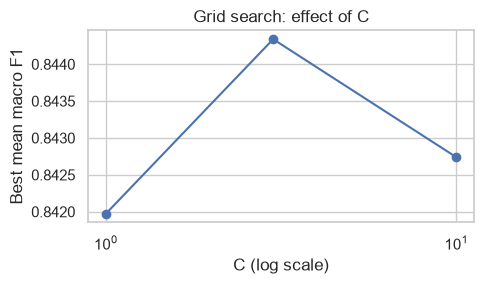

In [25]:
# Effect of the regularization strength C (best score per value)
c_effect = results.groupby('param_classifier__C')['mean_test_score'].max()
ax = c_effect.plot(marker='o', figsize=(5, 3))
ax.set_xscale('log')
ax.set_xlabel('C (log scale)')
ax.set_ylabel('Best mean macro F1')
ax.set_title('Grid search: effect of C')
plt.tight_layout()
plt.show()

The table and plot show how much each setting matters. The scores of the best combinations lie close together, so the pipeline is not very sensitive to these parameters; the regularization strength `C` has the largest effect.

## Evaluating the Final Pipeline on the Test Data

The best pipeline from the grid search was retrained on all training data. Now it is used **once** on the test set (10 % of the data, never seen during training or tuning).

In [26]:
final_model = grid_search.best_estimator_
y_pred = final_model.predict(X_test)

print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(f'Macro F1: {f1_score(y_test, y_pred, average="macro"):.3f}\n')
print(classification_report(
    y_test, y_pred,
    target_names=['not recommended (0)', 'recommended (1)'],
    digits=3,
))

majority_accuracy = (y_test == 1).mean()
print(f'Reference: always predicting "recommended" gives '
      f'{majority_accuracy:.3f} accuracy')

Accuracy: 0.902
Macro F1: 0.845

                     precision    recall  f1-score   support

not recommended (0)      0.683     0.832     0.750       327
    recommended (1)      0.962     0.917     0.939      1518

           accuracy                          0.902      1845
          macro avg      0.823     0.874     0.845      1845
       weighted avg      0.913     0.902     0.906      1845

Reference: always predicting "recommended" gives 0.823 accuracy


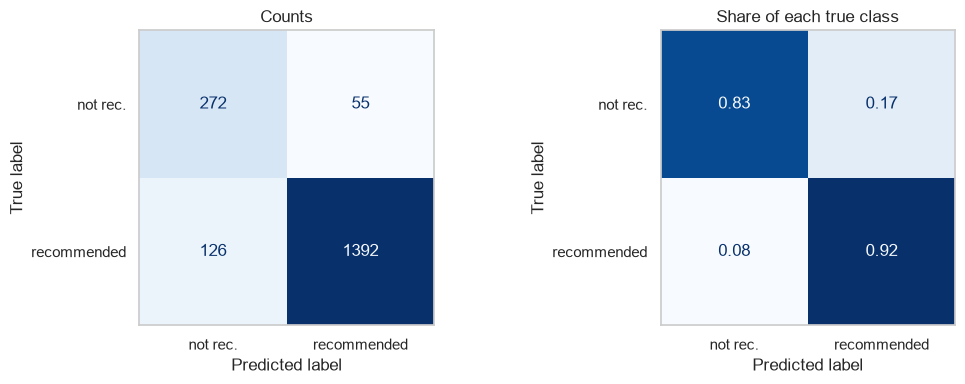

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, normalize, title in [
    (axes[0], None, 'Counts'),
    (axes[1], 'true', 'Share of each true class'),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=['not rec.', 'recommended'],
        normalize=normalize,
        values_format='d' if normalize is None else '.2f',
        cmap='Blues',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(title)
    ax.grid(False)
plt.tight_layout()
plt.show()

### Which features drive the predictions?

Logistic regression assigns one coefficient per feature. Positive coefficients push a review towards *recommended*, negative ones towards *not recommended*.

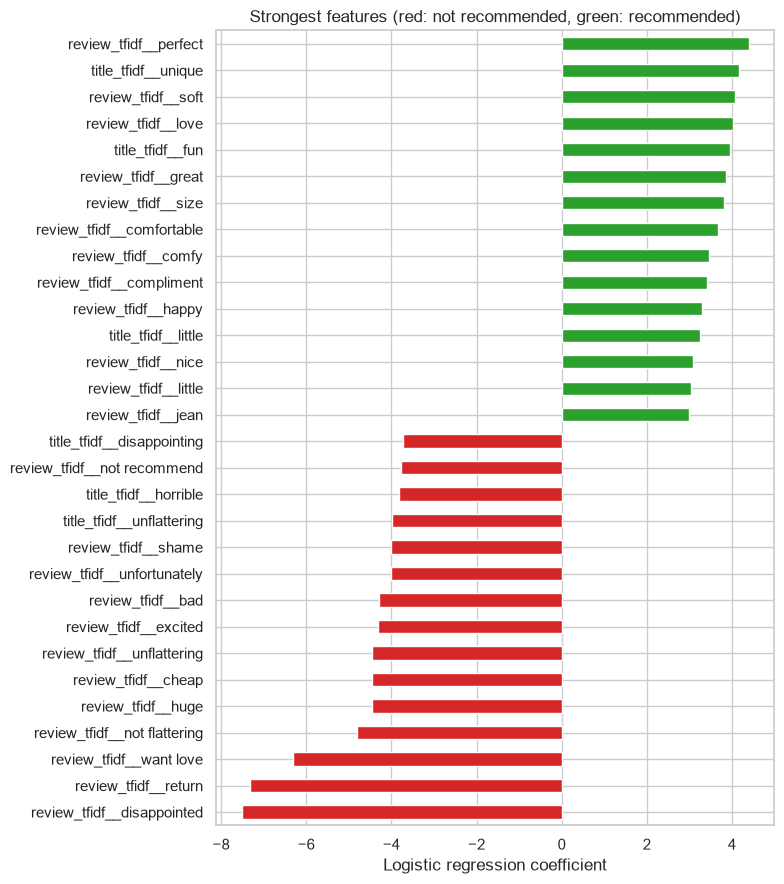

In [28]:
def top_coefficients(pipeline, n=15):
    """Return the n most positive and n most negative coefficients."""
    names = pipeline.named_steps['features'].get_feature_names_out()
    coefficients = pd.Series(
        pipeline.named_steps['classifier'].coef_[0], index=names,
    )
    return pd.concat(
        [coefficients.nsmallest(n), coefficients.nlargest(n)[::-1]]
    )


top = top_coefficients(final_model)
colors = ['tab:red' if value < 0 else 'tab:green' for value in top]
ax = top.plot(kind='barh', color=colors, figsize=(8, 9))
ax.set_title('Strongest features (red: not recommended, green: recommended)')
ax.set_xlabel('Logistic regression coefficient')
plt.tight_layout()
plt.show()

In [29]:
# Coefficients of the engineered (non-TF-IDF) text features
names = final_model.named_steps['features'].get_feature_names_out()
coefficients = pd.Series(
    final_model.named_steps['classifier'].coef_[0], index=names,
)
engineered = coefficients[
    coefficients.index.str.startswith(('text_stats__', 'adjectives__',
                                       'numeric__'))
]
engineered.sort_values().round(3).to_frame('coefficient')

,coefficient
text_stats__Title_negations,-0.279
text_stats__Review Text_negations,-0.120
numeric__Positive Feedback Count,-0.104
text_stats__Title_word_count,-0.100
numeric__Age,0.032
text_stats__Review Text_word_count,0.070
adjectives__Review Text_adjectives,0.119
adjectives__Title_adjectives,0.134
text_stats__Title_exclamations,0.171
text_stats__Review Text_exclamations,0.192


### Error analysis

A few test reviews the model got wrong:

In [30]:
errors = X_test.assign(true=y_test, predicted=y_pred)
errors = errors[errors['true'] != errors['predicted']]
print(f'{len(errors)} of {len(X_test)} test reviews are misclassified\n')

for true_label in [0, 1]:
    sample = errors[errors['true'] == true_label].head(2)
    for _, row in sample.iterrows():
        print(f'True: {row["true"]}, predicted: {row["predicted"]} | '
              f'{row["Title"]}: {row["Review Text"][:220]}...\n')

181 of 1845 test reviews are misclassified

True: 0, predicted: 1 | Beautiful, but....: This skirt is beautiful. fabric is gorgeous,with perfect amount of shine and luxury to it. there is a "life "in this skirt; it is well made and follows the body lines in a perfect way. or,i better say, it did fit me perf...

True: 0, predicted: 1 | Cute pant: Unfortunately i had to size down twice with there pants. great feel, they're soft and the grey is a soft color....

True: 1, predicted: 0 | Tall girls: The length of these pants is not quite long enough. i'm 5'8, and the only way i can make these work is if they're pulled low on the hips. it'd be nice if more brands offered long and short sizes in lounge...

True: 1, predicted: 0 | Awkward fit for me: Love the way these pants look in the pictures, great quality, but the style isn't really me. i gave it a try, so that's what counts!...



## Conclusion

**Results on the test set** (1,845 reviews, never used for training or tuning):

| Metric | Final pipeline | Always "recommended" |
|---|---|---|
| Accuracy | 0.902 | 0.823 |
| Macro F1 | 0.845 | about 0.45 |
| Recall, not recommended | 0.832 | 0.000 |
| Precision, not recommended | 0.683 | – |
| Recall, recommended | 0.917 | 1.000 |

- The test scores match the cross-validation scores (macro F1 0.844), so the
  pipeline generalizes well and does not overfit.
- The model finds **83 %** of the reviews whose authors do not recommend the
  product. That is the group StyleSense cares most about. The price is some
  false alarms: about one in three reviews flagged as *not recommended* was
  actually recommended.
- Fine-tuning improved macro F1 only slightly (0.841 → 0.844), so the default
  settings were already reasonable. The best model uses `C=3`, a review
  vocabulary of up to 20,000 terms, and terms that appear in at least 2 reviews.

**What drives the predictions.** The review text matters most. Words like
*perfect*, *love* and *comfortable* point to a recommendation, while
*disappointed*, *return* and *unflattering* point against it. Several of the
strongest signals are word pairs that only exist because negations were kept
during text cleaning: *not flattering*, *not recommend*, and *want love* (as
in "I wanted to love it"). Among the engineered features, negations in the
title push towards *not recommended* and exclamation marks towards
*recommended*. Age and positive-feedback count matter little, as the data
exploration suggested.

**Limitations and next steps.** Most errors are mixed reviews: praise for the
material combined with a fit problem, or a recommendation despite complaints
about length. A bag-of-words model cannot weigh such opposing statements well.
Possible next steps are adjusting the decision threshold to trade recall for
precision depending on StyleSense's needs, trying other classifiers (e.g.
linear SVM or gradient boosting), or using sentence embeddings or a
fine-tuned transformer model that understands context better.